In [ ]:
# Install Ultralytics library for YOLO training
!pip install -q ultralytics

import torch

# Check if GPU is enabled
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device Name:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.3/65.3 kB 4.3 MB/s eta 0:00:00
CUDA Available: True
GPU Device Name: Tesla T4


In [ ]:
import glob
import os
import shutil
import urllib.request
import zipfile
from sklearn.model_selection import train_test_split

# 1. Download verified Pothole YOLO dataset release
dataset_url = "https://github.com/jaygala24/pothole-detection/releases/download/v1.0.0/Pothole.Dataset.IVCNZ.zip"
zip_path = "potholes.zip"

print("Downloading dataset... ⏳")
urllib.request.urlretrieve(dataset_url, zip_path)

print("Extracting files... 📂")
with zipfile.ZipFile(zip_path, "r") as zip_ref:
  zip_ref.extractall("raw_data")

if os.path.exists(zip_path):
  os.remove(zip_path)

# 2. Organize files into YOLO structure
images = sorted(glob.glob("raw_data/Pothole Dataset/*.jpg"))
labels = [f.replace(".jpg", ".txt") for f in images]

train_imgs, val_imgs = train_test_split(images, test_size=0.2, random_state=42)

for split, img_list in [("train", train_imgs), ("valid", val_imgs)]:
  os.makedirs(f"dataset/images/{split}", exist_ok=True)
  os.makedirs(f"dataset/labels/{split}", exist_ok=True)
  for img in img_list:
    txt = img.replace(".jpg", ".txt")
    shutil.copy(img, f"dataset/images/{split}/")
    if os.path.exists(txt):
      shutil.copy(txt, f"dataset/labels/{split}/")

# 3. Create dataset configuration YAML file
yaml_content = f"""
path: {os.path.abspath('dataset')}
train: images/train
val: images/valid
names:
  0: pothole
"""
with open("dataset/data.yaml", "w") as f:
  f.write(yaml_content.strip())

print("Dataset successfully extracted and formatted! ✅")

Extracting files... 📂
Dataset successfully extracted and formatted! ✅


In [ ]:
from ultralytics import YOLO

# 1. Load pre-trained YOLOv8-nano model
model = YOLO('yolov8n.pt')

# 2. Train on the pothole dataset
results = model.train(
    data='dataset/data.yaml',
    epochs=40,
    imgsz=416,        # Scaled for fast inference on Banana Pi BPI-M4
    batch=16,
    name='pothole_model',
    device=0
)

print("Training finished successfully! 🎉")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics 8.4.128 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchs

In [ ]:
import shutil
from google.colab import files
from ultralytics import YOLO

# 1. Load the best trained model
trained_model = YOLO("runs/detect/pothole_model/weights/best.pt")

# 2. Export to NCNN (fastest on Banana Pi BPI-M4)
print("Exporting to NCNN... ⚙️")
trained_model.export(format="ncnn", imgsz=416)

# 3. Export to ONNX (flexible alternative)
print("Exporting to ONNX... ⚙️")
trained_model.export(format="onnx", imgsz=416)

# 4. Zip all exported models for easy download
print("Compressing models... 📦")
shutil.make_archive(
    "pothole_bpi_models", "zip", "runs/detect/pothole_model/weights"
)

# 5. Trigger browser download
files.download("pothole_bpi_models.zip")
print("Download ready! ✅")

Exporting to NCNN... ⚙️
Ultralytics 8.4.128 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
WARNING ⚠️ NCNN export does not support end2end models, disabling end2end branch.
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 3.4 GFLOPs

PyTorch: starting from 'runs/detect/pothole_model/weights/best.pt' with input shape (1, 3, 416, 416) BCHW and output shape(s) (1, 5, 3549) (5.9 MB)
requirements: Ultralytics requirement ['ncnn'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 1 package in 518ms
Prepared 1 package in 435ms
Installed 1 package in 8ms
 + ncnn==1.0.20260526

requirements: AutoUpdate success ✅ 1.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

requirements: Ultralytics requirement ['pnnx==20260526'] not found, attempting A

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download ready! ✅


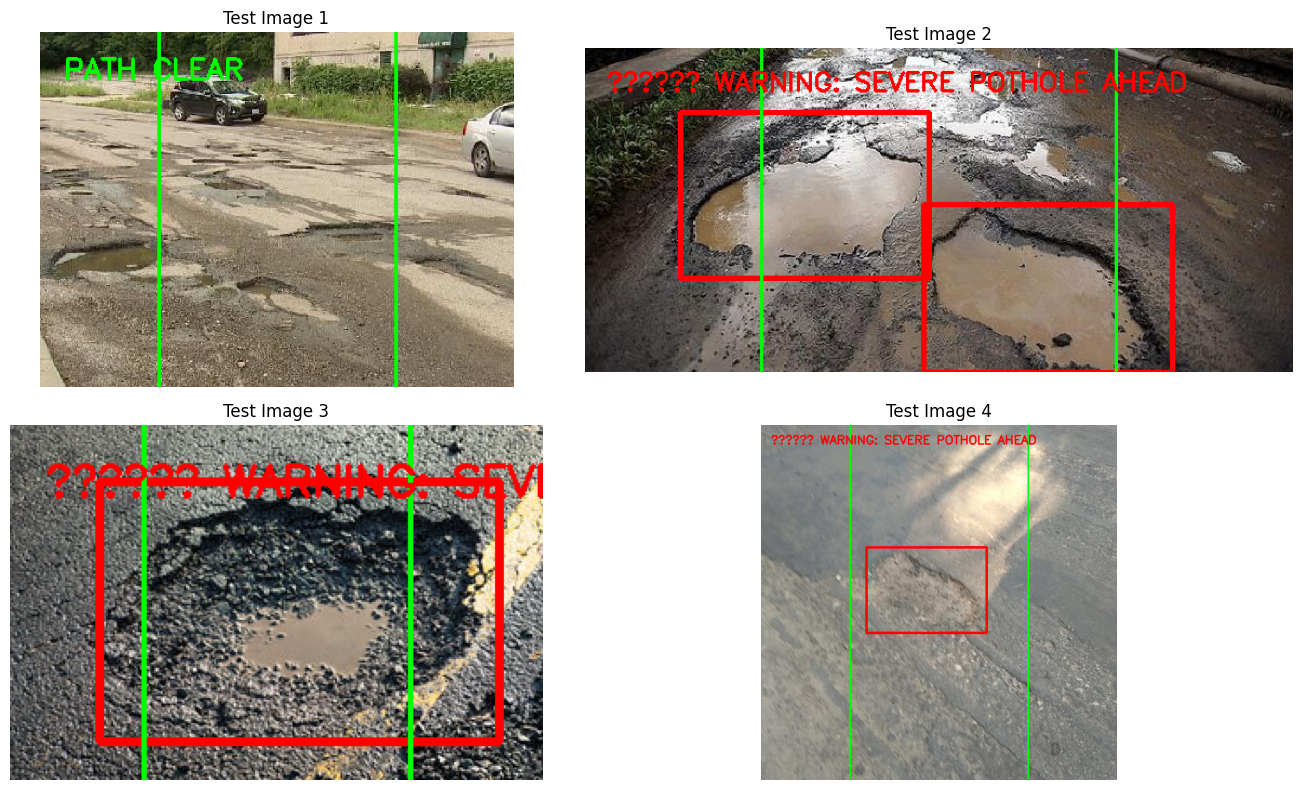

In [ ]:
import glob
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Load the trained best model
model = YOLO('runs/detect/pothole_model/weights/best.pt')

# 2. Grab a few validation images
val_images = glob.glob('dataset/images/valid/*.jpg')[:4]

# Rider Lane & Danger Parameters
MIN_AREA_DANGER = 2500  # Minimum pixel area for severe potholes

plt.figure(figsize=(14, 8))

for idx, img_path in enumerate(val_images):
  frame = cv2.imread(img_path)
  h_orig, w_orig, _ = frame.shape

  # Define center lane (50% center path)
  lane_x_min = int(w_orig * 0.25)
  lane_x_max = int(w_orig * 0.75)

  # Run prediction with high confidence threshold to prioritize accuracy
  results = model.predict(source=frame, conf=0.60, verbose=False)

  alert_triggered = False

  for r in results:
    for box in r.boxes:
      x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
      w = x2 - x1
      h = y2 - y1
      area = w * h
      box_center_x = (x1 + x2) / 2

      # Check if hazard is severe and in rider line of path
      if (lane_x_min <= box_center_x <= lane_x_max) and (
          area >= MIN_AREA_DANGER
      ):
        alert_triggered = True
        # Draw red box around the dangerous pothole
        cv2.rectangle(
            frame,
            (int(x1), int(y1)),
            (int(x2), int(y2)),
            (0, 0, 255),
            3,
        )

  # Draw Rider Path Boundary Lines (Green guides)
  cv2.line(
      frame,
      (lane_x_min, 0),
      (lane_x_min, h_orig),
      (0, 255, 0),
      2,
  )
  cv2.line(
      frame,
      (lane_x_max, 0),
      (lane_x_max, h_orig),
      (0, 255, 0),
      2,
  )

  # Non-distracting clean HUD status at the top
  if alert_triggered:
    cv2.putText(
        frame,
        '⚠️ WARNING: SEVERE POTHOLE AHEAD',
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 255),
        2,
    )
  else:
    cv2.putText(
        frame,
        'PATH CLEAR',
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2,
    )

  # Plot in grid
  plt.subplot(2, 2, idx + 1)
  plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
  plt.axis('off')
  plt.title(f'Test Image {idx+1}')

plt.tight_layout()
plt.show()

In [ ]:
from ultralytics import YOLO

# 1. Load the best trained model
model = YOLO('runs/detect/pothole_model/weights/best.pt')

# 2. Run formal evaluation on the validation split
metrics = model.val(data='dataset/data.yaml', imgsz=416, conf=0.50, iou=0.60)

# 3. Print clean performance summary
print("\n" + "=" * 45)
print("🎯 POTHOLE DETECTION ACCURACY REPORT")
print("=" * 45)
print(f"Precision (How many detected were real) : {metrics.box.p[0]*100:.2f}%")
print(f"Recall    (How many real ones it caught): {metrics.box.r[0]*100:.2f}%")
print(f"mAP@50    (Overall detection accuracy)  : {metrics.box.map50*100:.2f}%")
print(f"mAP@50-95 (Strict high-accuracy metric) : {metrics.box.map*100:.2f}%")
print("=" * 45)

Ultralytics 8.4.128 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2545.6±899.4 MB/s, size: 64.8 KB)
val: Scanning /content/dataset/labels/valid.cache... 249 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 249/249 61.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.8it/s 4.2s
                   all        249        807      0.866       0.41      0.386      0.206
Speed: 1.8ms preprocess, 6.3ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs/detect/val

🎯 POTHOLE DETECTION ACCURACY REPORT
Precision (How many detected were real) : 86.65%
Recall    (How many real ones it caught): 41.02%
mAP@50    (Overall detection accuracy)  : 38.64%
mAP@50-95 (Strict high-accuracy metric) : 20.56%


In [ ]:
import glob
import os
import cv2
from google.colab import files
from ultralytics import YOLO

# 1. Load trained model
model = YOLO('runs/detect/pothole_model/weights/best.pt')

# 2. Grab all validation test images
val_images = sorted(glob.glob('dataset/images/valid/*.jpg'))
if not val_images:
  raise FileNotFoundError(
      "Validation images not found! Make sure Step 3 was executed."
  )

# Video settings
frame_sample = cv2.imread(val_images[0])
height, width, _ = frame_sample.shape
fps = 4  # 4 frames per second to inspect each test case clearly

output_video_path = 'pothole_alert_simulation.mp4'
out = cv2.VideoWriter(
    output_video_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (width, height)
)

# Lane parameters
lane_x_min = int(width * 0.25)
lane_x_max = int(width * 0.75)
MIN_AREA_DANGER = 2200

print(f'Generating simulation video from {len(val_images)} test frames... 🎥')

for img_path in val_images:
  frame = cv2.imread(img_path)
  if frame is None:
    continue
  frame = cv2.resize(frame, (width, height))

  # Run inference with high confidence threshold
  results = model.predict(source=frame, conf=0.55, verbose=False)
  danger_alert = False

  for r in results:
    for box in r.boxes:
      x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
      w = x2 - x1
      h = y2 - y1
      area = w * h
      box_center_x = (x1 + x2) / 2

      # Check if hazard is severe and inside rider path
      if (lane_x_min <= box_center_x <= lane_x_max) and (
          area >= MIN_AREA_DANGER
      ):
        danger_alert = True
        cv2.rectangle(
            frame, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 3
        )

  # Lane boundary visualization
  cv2.line(frame, (lane_x_min, 0), (lane_x_min, height), (0, 255, 0), 2)
  cv2.line(frame, (lane_x_max, 0), (lane_x_max, height), (0, 255, 0), 2)

  # Clean HUD status banner
  if danger_alert:
    cv2.rectangle(frame, (10, 10), (460, 60), (0, 0, 180), -1)
    cv2.putText(
        frame,
        '⚠️ DANGER: POTHOLE IN LANE',
        (20, 45),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 255, 255),
        2,
    )
  else:
    cv2.rectangle(frame, (10, 10), (220, 60), (0, 140, 0), -1)
    cv2.putText(
        frame,
        'PATH CLEAR',
        (20, 45),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 255, 255),
        2,
    )

  out.write(frame)

out.release()
print('Simulation video created successfully! 🎉')

# Trigger browser download
files.download(output_video_path)

Generating simulation video from 249 test frames... 🎥
Simulation video created successfully! 🎉


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>